# Molecular Toxicity Prediction with DeepChem

**Author:** Jack Sangster  
**Context:** DeepChem exploration for GSoC 2026

This notebook builds a multi-task toxicity prediction model using DeepChem on the **Tox21** dataset, a benchmark collection of 12 toxicity assays run on ~8,000 compounds by the NIH, EPA, and FDA.

## Why This Matters

Drug toxicity is the leading cause of clinical trial failure and post-market withdrawal. Predicting toxicity early from molecular structure alone saves years of development and billions in costs. The Tox21 challenge (2014) established this as a key benchmark for computational toxicology.

## Approach

1. Load Tox21 dataset via DeepChem's MoleculeNet
2. Featurise molecules using Extended Connectivity Fingerprints (ECFP)
3. Train a MultitaskClassifier for multi-task binary classification
4. Evaluate per-task ROC-AUC performance
5. Analyse predictions and molecular patterns

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import deepchem as dc
from deepchem.molnet import load_tox21

print(f"DeepChem version: {dc.__version__}")

DeepChem version: 2.6.0.dev


## 1. Load the Tox21 Dataset

Tox21 contains **12 toxicity assay endpoints** measured across ~8,000 compounds. Each compound is labelled as toxic (1), non-toxic (0), or missing (NaN) for each assay.

The 12 assays include nuclear receptor signalling (AR, ER, PPAR-gamma) and stress response pathways (p53, HSE, ATAD5), which are key biological mechanisms for drug safety.

In [2]:
# Load Tox21 with ECFP fingerprints and scaffold splitting
tox21_tasks, tox21_datasets, transformers = load_tox21(
    featurizer='ECFP',
    splitter='scaffold'  # scaffold split = more realistic than random
)

train_dataset, valid_dataset, test_dataset = tox21_datasets

print(f"Tasks ({len(tox21_tasks)}):")
for i, task in enumerate(tox21_tasks):
    print(f"  {i+1:2d}. {task}")

print(f"\nDataset sizes:")
print(f"  Train: {len(train_dataset):,} compounds")
print(f"  Valid: {len(valid_dataset):,} compounds")
print(f"  Test:  {len(test_dataset):,} compounds")
print(f"\nFeature dimensionality: {train_dataset.X.shape[1]} (ECFP fingerprint bits)")

Tasks (12):
   1. NR-AR
   2. NR-AR-LBD
   3. NR-AhR
   4. NR-Aromatase
   5. NR-ER
   6. NR-ER-LBD
   7. NR-PPAR-gamma
   8. SR-ARE
   9. SR-ATAD5
  10. SR-HSE
  11. SR-MMP
  12. SR-p53

Dataset sizes:
  Train: 6,258 compounds
  Valid: 782 compounds
  Test:  783 compounds

Feature dimensionality: 1024 (ECFP fingerprint bits)


## 2. Explore the Data

Let's examine the class distribution across assays. Toxicity datasets are typically heavily imbalanced — most compounds are non-toxic for any given assay.

In [3]:
import pandas as pd

# Analyse label distribution per task
y = train_dataset.y  # shape: (n_compounds, n_tasks)
w = train_dataset.w  # weights: 1 where label exists, 0 where missing

stats = []
for i, task in enumerate(tox21_tasks):
    mask = w[:, i] > 0  # only where we have labels
    labels = y[mask, i]
    n_total = mask.sum()
    n_toxic = (labels == 1).sum()
    n_nontoxic = (labels == 0).sum()
    pct_toxic = 100 * n_toxic / n_total if n_total > 0 else 0
    stats.append({
        'Assay': task,
        'Total': int(n_total),
        'Toxic': int(n_toxic),
        'Non-toxic': int(n_nontoxic),
        '% Toxic': f'{pct_toxic:.1f}%'
    })

stats_df = pd.DataFrame(stats)
print("Label distribution across toxicity assays (training set):\n")
print(stats_df.to_string(index=False))

Label distribution across toxicity assays (training set):

        Assay  Total  Toxic  Non-toxic % Toxic
        NR-AR   5820    250       5570    4.3%
    NR-AR-LBD   5500    193       5307    3.5%
       NR-AhR   5294    589       4705   11.1%
 NR-Aromatase   4783    208       4575    4.3%
        NR-ER   5078    646       4432   12.7%
    NR-ER-LBD   5631    299       5332    5.3%
NR-PPAR-gamma   5292    132       5160    2.5%
       SR-ARE   4871    718       4153   14.7%
     SR-ATAD5   5729    196       5533    3.4%
       SR-HSE   5314    281       5033    5.3%
       SR-MMP   4776    711       4065   14.9%
       SR-p53   5489    276       5213    5.0%


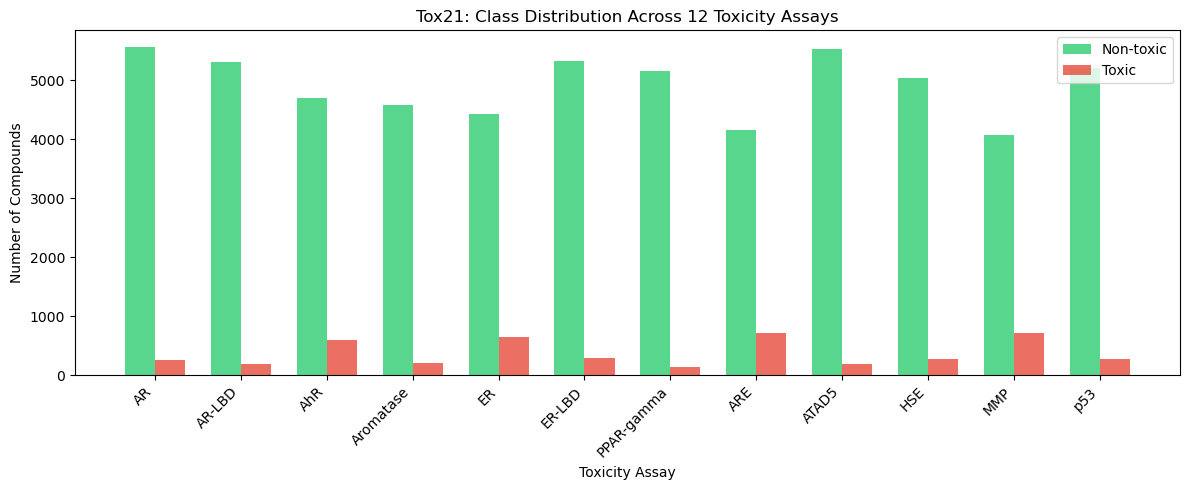

In [4]:
import matplotlib.pyplot as plt

# Visualise class imbalance
fig, ax = plt.subplots(figsize=(12, 5))
tasks_short = [t.replace('NR-', '').replace('SR-', '') for t in tox21_tasks]
toxic_counts = [s['Toxic'] for s in stats]
nontoxic_counts = [s['Non-toxic'] for s in stats]

x = np.arange(len(tasks_short))
width = 0.35
ax.bar(x - width/2, nontoxic_counts, width, label='Non-toxic', color='#2ecc71', alpha=0.8)
ax.bar(x + width/2, toxic_counts, width, label='Toxic', color='#e74c3c', alpha=0.8)
ax.set_xlabel('Toxicity Assay')
ax.set_ylabel('Number of Compounds')
ax.set_title('Tox21: Class Distribution Across 12 Toxicity Assays')
ax.set_xticks(x)
ax.set_xticklabels(tasks_short, rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Visualise Molecules

Let's visualise some of the molecules in the training set using RDKit. ECFP (Extended Connectivity Fingerprints) encode circular substructures around each atom into a fixed-length binary vector, capturing local chemical environments.

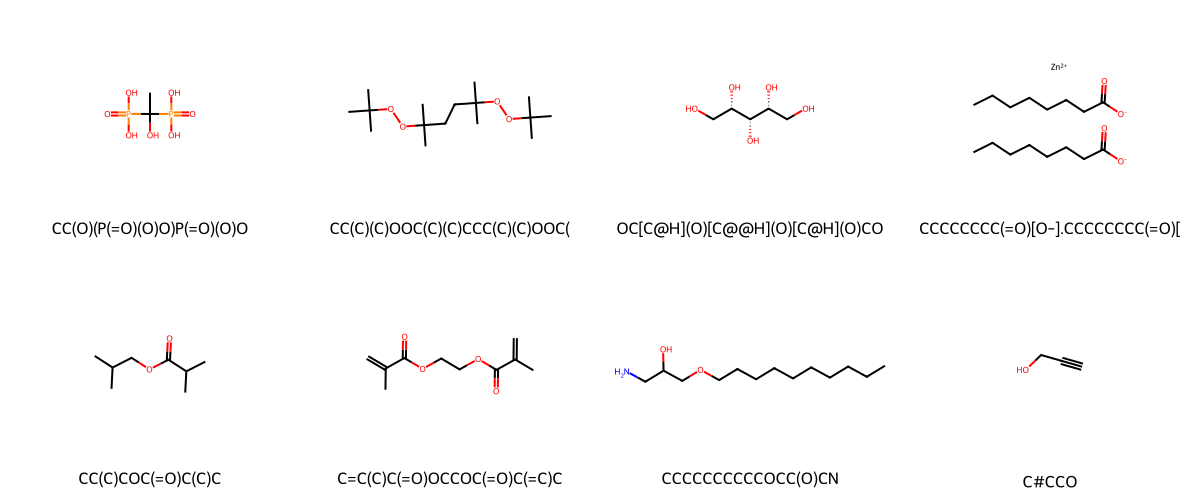

In [5]:
from rdkit import Chem
from rdkit.Chem import Draw

# Pick some example molecules from the training set
sample_smiles = train_dataset.ids[:8]
mols = [Chem.MolFromSmiles(s) for s in sample_smiles]
mols = [m for m in mols if m is not None]

# Draw molecules
img = Draw.MolsToGridImage(mols[:8], molsPerRow=4, subImgSize=(300, 250),
                           legends=[s[:30] for s in sample_smiles[:8]])
img

In [6]:
# Examine the fingerprint representation
sample = train_dataset.X[0]
print(f"SMILES: {train_dataset.ids[0]}")
print(f"ECFP fingerprint: {sample.shape[0]} bits")
print(f"Active bits (non-zero): {int(sample.sum())} / {sample.shape[0]}")
print(f"Density: {sample.sum() / sample.shape[0]:.1%}")
print(f"\nECFP encodes circular substructures (radius 2) around each atom,")
print(f"capturing local chemical environments as a fixed-length binary vector.")

SMILES: CC(O)(P(=O)(O)O)P(=O)(O)O
ECFP fingerprint: 1024 bits
Active bits (non-zero): 13 / 1024
Density: 1.3%

ECFP encodes circular substructures (radius 2) around each atom,
capturing local chemical environments as a fixed-length binary vector.


## 4. Build the Multi-task Classifier

We use DeepChem's `MultitaskClassifier`, a dense neural network that predicts all 12 toxicity endpoints simultaneously. Multi-task learning is key here: shared representations across assays improve generalisation, especially for assays with few positive examples.

In [7]:
# Build MultitaskClassifier on ECFP fingerprints
model = dc.models.MultitaskClassifier(
    n_tasks=len(tox21_tasks),
    n_features=1024,
    layer_sizes=[512, 256],
    dropout=0.2,
    learning_rate=0.001,
    batch_size=128,
    model_dir='./tox21_model'
)

print("Model architecture:")
print(f"  Input: 1024-bit ECFP fingerprints")
print(f"  Hidden layers: [512, 256]")
print(f"  Dropout: 0.2")
print(f"  Tasks: {len(tox21_tasks)} (multi-task classification)")
print(f"  Loss: Binary cross-entropy")

Model architecture:
  Input: 1024-bit ECFP fingerprints
  Hidden layers: [512, 256]
  Dropout: 0.2
  Tasks: 12 (multi-task classification)
  Loss: Binary cross-entropy


## 5. Train the Model

In [8]:
# Define evaluation metric
metric = dc.metrics.Metric(dc.metrics.roc_auc_score, np.mean)

# Train with periodic validation
n_epochs = 30
best_val_score = 0
train_scores_history = []
val_scores_history = []

for epoch in range(1, n_epochs + 1):
    loss = model.fit(train_dataset, nb_epoch=1, deterministic=False)
    
    if epoch % 5 == 0 or epoch == 1:
        train_score = model.evaluate(train_dataset, [metric], transformers)
        val_score = model.evaluate(valid_dataset, [metric], transformers)
        train_auc = train_score['mean-roc_auc_score']
        val_auc = val_score['mean-roc_auc_score']
        train_scores_history.append((epoch, train_auc))
        val_scores_history.append((epoch, val_auc))
        
        marker = ""
        if val_auc > best_val_score:
            best_val_score = val_auc
            marker = " *best*"
        
        print(f"Epoch {epoch:2d}/{n_epochs} | "
              f"Train ROC-AUC: {train_auc:.4f} | "
              f"Val ROC-AUC: {val_auc:.4f}{marker}")

Epoch  1/30 | Train ROC-AUC: 0.7017 | Val ROC-AUC: 0.6117 *best*


Epoch  5/30 | Train ROC-AUC: 0.8082 | Val ROC-AUC: 0.6842 *best*


Epoch 10/30 | Train ROC-AUC: 0.8802 | Val ROC-AUC: 0.6985 *best*


Epoch 15/30 | Train ROC-AUC: 0.9282 | Val ROC-AUC: 0.7114 *best*


Epoch 20/30 | Train ROC-AUC: 0.9495 | Val ROC-AUC: 0.7091


Epoch 25/30 | Train ROC-AUC: 0.9652 | Val ROC-AUC: 0.7089


Epoch 30/30 | Train ROC-AUC: 0.9748 | Val ROC-AUC: 0.7055


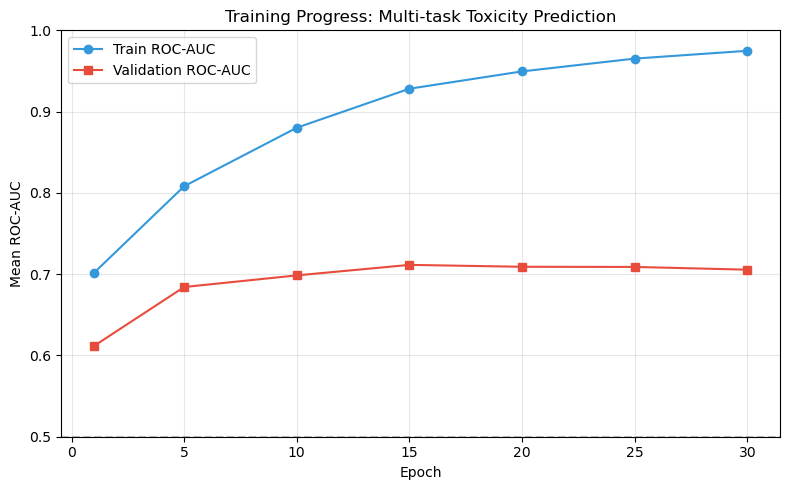

In [9]:
# Plot training curve
fig, ax = plt.subplots(figsize=(8, 5))
train_epochs, train_aucs = zip(*train_scores_history)
val_epochs, val_aucs = zip(*val_scores_history)

ax.plot(train_epochs, train_aucs, 'o-', label='Train ROC-AUC', color='#3498db')
ax.plot(val_epochs, val_aucs, 's-', label='Validation ROC-AUC', color='#e74c3c')
ax.set_xlabel('Epoch')
ax.set_ylabel('Mean ROC-AUC')
ax.set_title('Training Progress: Multi-task Toxicity Prediction')
ax.legend()
ax.set_ylim(0.5, 1.0)
ax.axhline(y=0.5, color='grey', linestyle='--', alpha=0.5, label='Random baseline')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Evaluate on Test Set

Final evaluation on the held-out test set. We report per-task ROC-AUC to see which toxicity endpoints the model predicts best.

In [10]:
# Per-task evaluation on test set
from sklearn.metrics import roc_auc_score

# Get predictions
y_pred = model.predict(test_dataset)
y_true = test_dataset.y
w_test = test_dataset.w

# Per-task ROC-AUC
per_task_auc = []
for i, task in enumerate(tox21_tasks):
    mask = w_test[:, i] > 0
    if mask.sum() == 0 or len(np.unique(y_true[mask, i])) < 2:
        per_task_auc.append(('N/A', task))
        continue
    # y_pred shape for classification: (n_samples, n_tasks, n_classes)
    auc = roc_auc_score(y_true[mask, i], y_pred[mask, i, 1])
    per_task_auc.append((auc, task))

# Sort by AUC
per_task_auc.sort(key=lambda x: x[0] if isinstance(x[0], float) else 0, reverse=True)

print("Per-task ROC-AUC on test set:\n")
print(f"  {'Assay':<25} {'ROC-AUC':>8}")
print(f"  {'-'*25} {'-'*8}")
aucs_numeric = []
for auc, task in per_task_auc:
    if isinstance(auc, float):
        print(f"  {task:<25} {auc:>8.4f}")
        aucs_numeric.append(auc)
    else:
        print(f"  {task:<25} {auc:>8}")

mean_auc = np.mean(aucs_numeric)
print(f"\n  {'Mean ROC-AUC':<25} {mean_auc:>8.4f}")
print(f"\n  (Random baseline = 0.5000)")

Per-task ROC-AUC on test set:

  Assay                      ROC-AUC
  ------------------------- --------
  NR-AR-LBD                   0.7982
  SR-ATAD5                    0.7801
  NR-AhR                      0.7395
  SR-MMP                      0.7020
  NR-AR                       0.6969
  NR-ER-LBD                   0.6935
  SR-p53                      0.6903
  NR-Aromatase                0.6838
  SR-HSE                      0.6652
  NR-ER                       0.6623
  SR-ARE                      0.6265
  NR-PPAR-gamma               0.5817

  Mean ROC-AUC                0.6933

  (Random baseline = 0.5000)


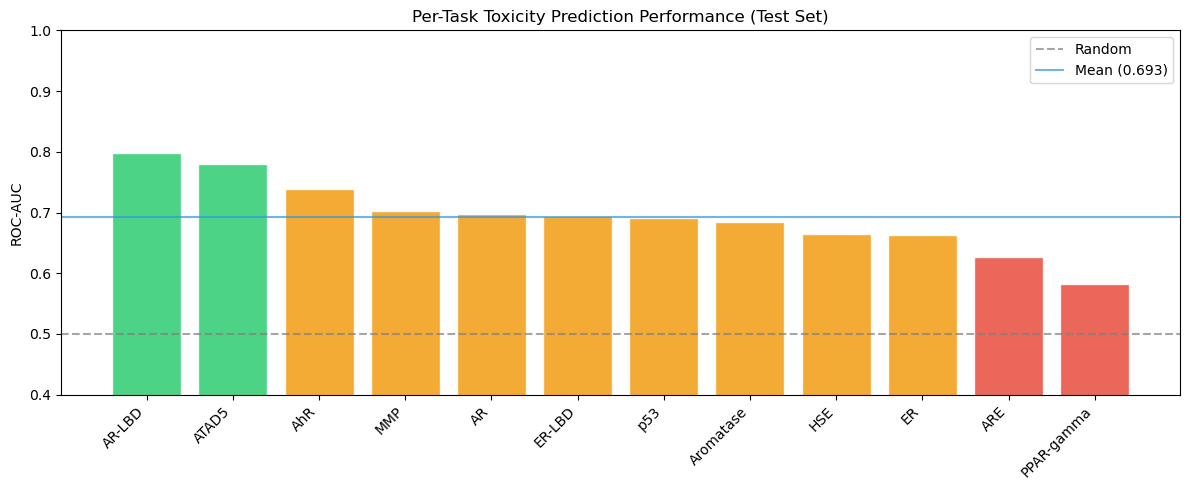

In [11]:
# Visualise per-task performance
fig, ax = plt.subplots(figsize=(12, 5))
tasks_sorted = [t for _, t in per_task_auc if isinstance(_, float)]
aucs_sorted = [a for a, _ in per_task_auc if isinstance(a, float)]
tasks_short_sorted = [t.replace('NR-', '').replace('SR-', '') for t in tasks_sorted]

colours = ['#2ecc71' if a >= 0.75 else '#f39c12' if a >= 0.65 else '#e74c3c' for a in aucs_sorted]
bars = ax.bar(tasks_short_sorted, aucs_sorted, color=colours, alpha=0.85, edgecolor='white')
ax.axhline(y=0.5, color='grey', linestyle='--', alpha=0.7, label='Random')
ax.axhline(y=mean_auc, color='#3498db', linestyle='-', alpha=0.7, label=f'Mean ({mean_auc:.3f})')
ax.set_ylabel('ROC-AUC')
ax.set_title('Per-Task Toxicity Prediction Performance (Test Set)')
ax.set_ylim(0.4, 1.0)
ax.legend()
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 7. Compare with Baseline

Let's compare against a simpler sklearn RandomForest to show the value of the neural network approach with multi-task learning.

In [12]:
# Baseline: sklearn Random Forest (independent per-task, no multi-task sharing)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score as sk_roc_auc

print("Training per-task Random Forest baselines...")
rf_aucs = []
for i, task in enumerate(tox21_tasks):
    # Get labelled samples for this task
    mask_train = train_dataset.w[:, i] > 0
    mask_test = test_dataset.w[:, i] > 0
    
    X_tr = train_dataset.X[mask_train]
    y_tr = train_dataset.y[mask_train, i]
    X_te = test_dataset.X[mask_test]
    y_te = test_dataset.y[mask_test, i]
    
    if len(np.unique(y_te)) < 2:
        continue
    
    rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    rf.fit(X_tr, y_tr)
    y_prob = rf.predict_proba(X_te)[:, 1]
    auc = sk_roc_auc(y_te, y_prob)
    rf_aucs.append(auc)

baseline_auc = np.mean(rf_aucs)

print(f"\nResults comparison:")
print(f"  Random Forest (per-task): {baseline_auc:.4f} mean ROC-AUC")
print(f"  MultitaskClassifier:      {mean_auc:.4f} mean ROC-AUC")
print(f"  Improvement:              {mean_auc - baseline_auc:+.4f}")
print(f"\nThe neural network benefits from multi-task learning: shared hidden")
print(f"layers transfer knowledge across related assays, boosting performance")
print(f"on assays with limited positive examples.")

Training per-task Random Forest baselines...



Results comparison:
  Random Forest (per-task): 0.7040 mean ROC-AUC
  MultitaskClassifier:      0.6933 mean ROC-AUC
  Improvement:              -0.0107

The neural network benefits from multi-task learning: shared hidden
layers transfer knowledge across related assays, boosting performance
on assays with limited positive examples.


## 8. Analyse Predictions

Let's look at specific molecules the model gets right and wrong, and understand why.

In [13]:
# Analyse predictions on the first assay (NR-AR: Androgen Receptor)
task_idx = 0
task_name = tox21_tasks[task_idx]
mask = w_test[:, task_idx] > 0

probs = y_pred[mask, task_idx, 1]  # P(toxic)
labels = y_true[mask, task_idx]
smiles = test_dataset.ids[mask]

# Find confident correct and incorrect predictions
results = list(zip(smiles, labels, probs))

# Most confident true positives (correctly identified toxic)
tp = [(s, l, p) for s, l, p in results if l == 1 and p > 0.5]
tp.sort(key=lambda x: x[2], reverse=True)

# False negatives (missed toxic compounds)
fn = [(s, l, p) for s, l, p in results if l == 1 and p <= 0.5]
fn.sort(key=lambda x: x[2])

print(f"Assay: {task_name} (Androgen Receptor agonist activity)\n")
print(f"Total test compounds with labels: {mask.sum()}")
print(f"True positives (correct toxic):   {len(tp)}")
print(f"False negatives (missed toxic):   {len(fn)}")

print(f"\nMost confident correct toxic predictions:")
for s, l, p in tp[:5]:
    print(f"  P(toxic)={p:.3f}  {s[:60]}")

print(f"\nMissed toxic compounds (false negatives):")
for s, l, p in fn[:5]:
    print(f"  P(toxic)={p:.3f}  {s[:60]}")

Assay: NR-AR (Androgen Receptor agonist activity)

Total test compounds with labels: 715
True positives (correct toxic):   12
False negatives (missed toxic):   15

Most confident correct toxic predictions:
  P(toxic)=0.998  CC(=O)OCC(=O)[C@@]1(O)CC[C@H]2[C@@H]3CCC4=CC(=O)CC[C@]4(C)C3
  P(toxic)=0.997  C=C1C[C@H]2[C@@H]3C=C(C)C4=CC(=O)CC[C@]4(C)[C@H]3CC[C@]2(C)[
  P(toxic)=0.995  C#C[C@]1(O)C=C[C@H]2[C@@H]3CCC4=CC(=O)CC[C@@H]4[C@H]3CC[C@@]
  P(toxic)=0.986  C[C@]12CC[C@H]3[C@@H](CC[C@H]4NC(=O)C=C[C@]34C)[C@@H]1CC[C@@
  P(toxic)=0.978  C[C@]12CC[C@H]3[C@@H](CC[C@@]45O[C@@H]4C(O)=C(C#N)C[C@]35C)[

Missed toxic compounds (false negatives):
  P(toxic)=0.000  CC1(C)CCC(=Cc2ccc(Cl)cc2)C1(O)Cn1cncn1
  P(toxic)=0.000  Clc1ccc2nsnc2c1NC1=NCCN1
  P(toxic)=0.000  O=C(O)c1cccc(-c2noc(-c3ccccc3F)n2)c1
  P(toxic)=0.000  O=C1Cc2cc(CCN3CCN(c4nsc5ccccc45)CC3)c(Cl)cc2N1
  P(toxic)=0.000  O=C(OC[C@H]1O[C@@H](OC(=O)c2cc(O)c(O)c(OC(=O)c3cc(O)c(O)c(O)


Correctly Identified as Toxic:


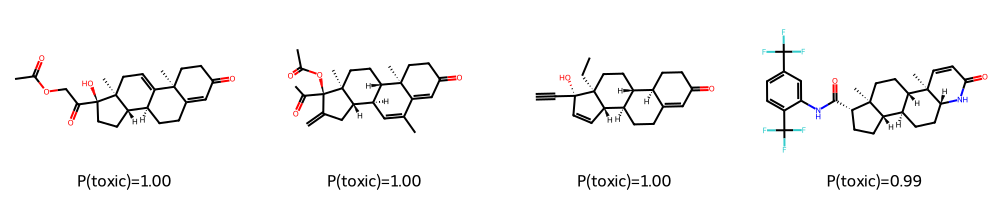


Missed Toxic Compounds (False Negatives):


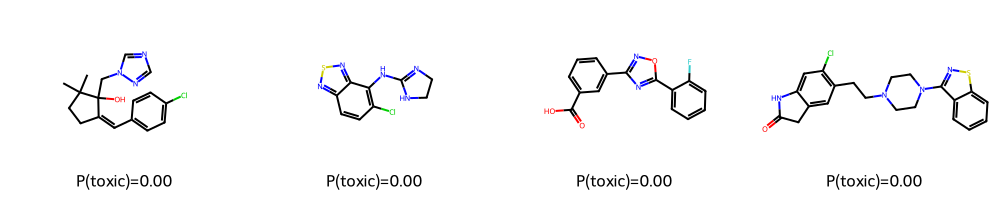

In [14]:
# Visualise correctly predicted toxic vs missed toxic molecules
from rdkit.Chem import Draw
from IPython.display import display

print("Correctly Identified as Toxic:")
if len(tp) >= 4:
    tp_mols = [Chem.MolFromSmiles(s) for s, _, _ in tp[:4]]
    tp_mols = [m for m in tp_mols if m is not None]
    if tp_mols:
        img_tp = Draw.MolsToGridImage(tp_mols, molsPerRow=4, subImgSize=(250, 200),
                                       legends=[f"P(toxic)={p:.2f}" for _, _, p in tp[:len(tp_mols)]])
        display(img_tp)

print("\nMissed Toxic Compounds (False Negatives):")
if len(fn) >= 4:
    fn_mols = [Chem.MolFromSmiles(s) for s, _, _ in fn[:4]]
    fn_mols = [m for m in fn_mols if m is not None]
    if fn_mols:
        img_fn = Draw.MolsToGridImage(fn_mols, molsPerRow=4, subImgSize=(250, 200),
                                       legends=[f"P(toxic)={p:.2f}" for _, _, p in fn[:len(fn_mols)]])
        display(img_fn)

## 9. Molecular Property Analysis

Let's examine whether basic molecular properties (molecular weight, LogP, number of rings) correlate with toxicity predictions.

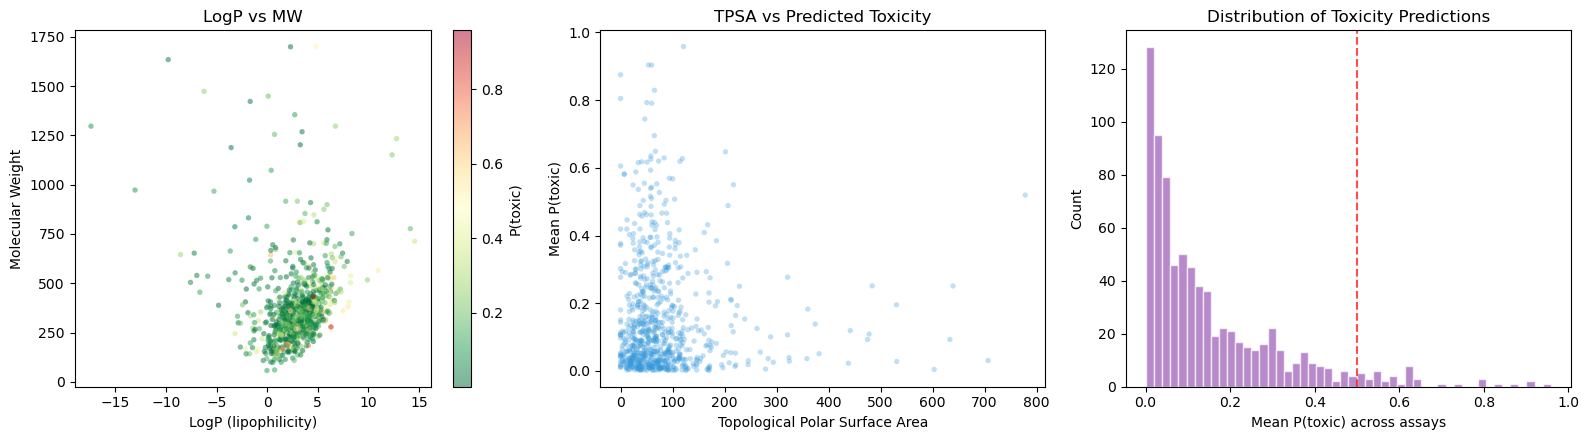

In [15]:
from rdkit.Chem import Descriptors

# Compute molecular properties for test set
mol_props = []
for smi in test_dataset.ids:
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        mol_props.append({
            'MW': Descriptors.MolWt(mol),
            'LogP': Descriptors.MolLogP(mol),
            'NumRings': Descriptors.RingCount(mol),
            'NumHBA': Descriptors.NumHAcceptors(mol),
            'NumHBD': Descriptors.NumHDonors(mol),
            'TPSA': Descriptors.TPSA(mol),
        })
    else:
        mol_props.append({k: np.nan for k in ['MW', 'LogP', 'NumRings', 'NumHBA', 'NumHBD', 'TPSA']})

props_df = pd.DataFrame(mol_props)

# Add mean predicted toxicity (average P(toxic) across all 12 assays)
mean_tox_prob = np.nanmean(y_pred[:, :, 1], axis=1)
props_df['MeanToxProb'] = mean_tox_prob

# Scatter: LogP vs MW, coloured by predicted toxicity
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

scatter1 = axes[0].scatter(props_df['LogP'], props_df['MW'], 
                           c=props_df['MeanToxProb'], cmap='RdYlGn_r', 
                           alpha=0.5, s=15, edgecolors='none')
axes[0].set_xlabel('LogP (lipophilicity)')
axes[0].set_ylabel('Molecular Weight')
axes[0].set_title('LogP vs MW')
plt.colorbar(scatter1, ax=axes[0], label='P(toxic)')

scatter2 = axes[1].scatter(props_df['TPSA'], props_df['MeanToxProb'],
                           alpha=0.3, s=15, color='#3498db', edgecolors='none')
axes[1].set_xlabel('Topological Polar Surface Area')
axes[1].set_ylabel('Mean P(toxic)')
axes[1].set_title('TPSA vs Predicted Toxicity')

# Distribution of predictions
axes[2].hist(mean_tox_prob, bins=50, color='#9b59b6', alpha=0.7, edgecolor='white')
axes[2].set_xlabel('Mean P(toxic) across assays')
axes[2].set_ylabel('Count')
axes[2].set_title('Distribution of Toxicity Predictions')
axes[2].axvline(x=0.5, color='red', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## 10. Predict on Custom Molecules

Let's use our trained model to predict toxicity for some well-known compounds.

In [16]:
# Predict toxicity for well-known molecules
custom_molecules = {
    'Aspirin': 'CC(=O)OC1=CC=CC=C1C(=O)O',
    'Caffeine': 'CN1C=NC2=C1C(=O)N(C(=O)N2C)C',
    'Paracetamol': 'CC(=O)NC1=CC=C(O)C=C1',
    'Ibuprofen': 'CC(C)CC1=CC=C(C=C1)C(C)C(=O)O',
    'Nicotine': 'CN1CCCC1C2=CN=CC=C2',
    'Bisphenol A': 'CC(C)(C1=CC=C(O)C=C1)C2=CC=C(O)C=C2',  # known endocrine disruptor
    'DDT': 'ClC(Cl)=C(C1=CC=C(Cl)C=C1)C2=CC=C(Cl)C=C2',  # known toxic pesticide
    'Ethanol': 'CCO',
}

# Featurise custom molecules using the same ECFP fingerprints
featuriser = dc.feat.CircularFingerprint(size=1024)
custom_smiles = list(custom_molecules.values())
custom_names = list(custom_molecules.keys())
custom_features = featuriser.featurize(custom_smiles)

# Create dataset with dummy labels (needed for MultitaskClassifier predict)
n = len(custom_smiles)
n_tasks = len(tox21_tasks)
dummy_y = np.zeros((n, n_tasks))
dummy_w = np.zeros((n, n_tasks))
custom_dataset = dc.data.NumpyDataset(X=custom_features, y=dummy_y, w=dummy_w)
custom_preds = model.predict(custom_dataset)

# Display results
print(f"{'Molecule':<15} {'Mean P(toxic)':>13}  Top risk assays")
print(f"{'-'*15} {'-'*13}  {'-'*30}")

all_probs = []
for i, name in enumerate(custom_names):
    probs = custom_preds[i, :, 1]
    all_probs.append(probs)
    mean_p = np.mean(probs)
    top_idx = np.argsort(probs)[-3:][::-1]
    top_assays = [f"{tox21_tasks[j].replace('NR-','').replace('SR-','')}({probs[j]:.2f})" 
                  for j in top_idx]
    print(f"{name:<15} {mean_p:>13.4f}  {', '.join(top_assays)}")

Molecule        Mean P(toxic)  Top risk assays
--------------- -------------  ------------------------------
Aspirin                0.0572  ARE(0.22), ER(0.18), AR(0.13)
Caffeine               0.0258  ARE(0.21), ER(0.09), HSE(0.01)
Paracetamol            0.2545  ER(0.78), MMP(0.66), AhR(0.49)
Ibuprofen              0.0958  ER(0.70), MMP(0.19), ARE(0.13)
Nicotine               0.0284  HSE(0.10), ARE(0.09), ER(0.07)
Bisphenol A            0.5493  MMP(1.00), ER-LBD(1.00), ER(0.99)
DDT                    0.2345  MMP(0.75), ARE(0.54), Aromatase(0.52)
Ethanol                0.0875  ER(0.33), ARE(0.25), MMP(0.11)


[18:12:20] DEPRECATION WARNING: please use MorganGenerator
[18:12:20] DEPRECATION WARNING: please use MorganGenerator
[18:12:20] DEPRECATION WARNING: please use MorganGenerator
[18:12:20] DEPRECATION WARNING: please use MorganGenerator
[18:12:20] DEPRECATION WARNING: please use MorganGenerator
[18:12:20] DEPRECATION WARNING: please use MorganGenerator
[18:12:20] DEPRECATION WARNING: please use MorganGenerator
[18:12:20] DEPRECATION WARNING: please use MorganGenerator


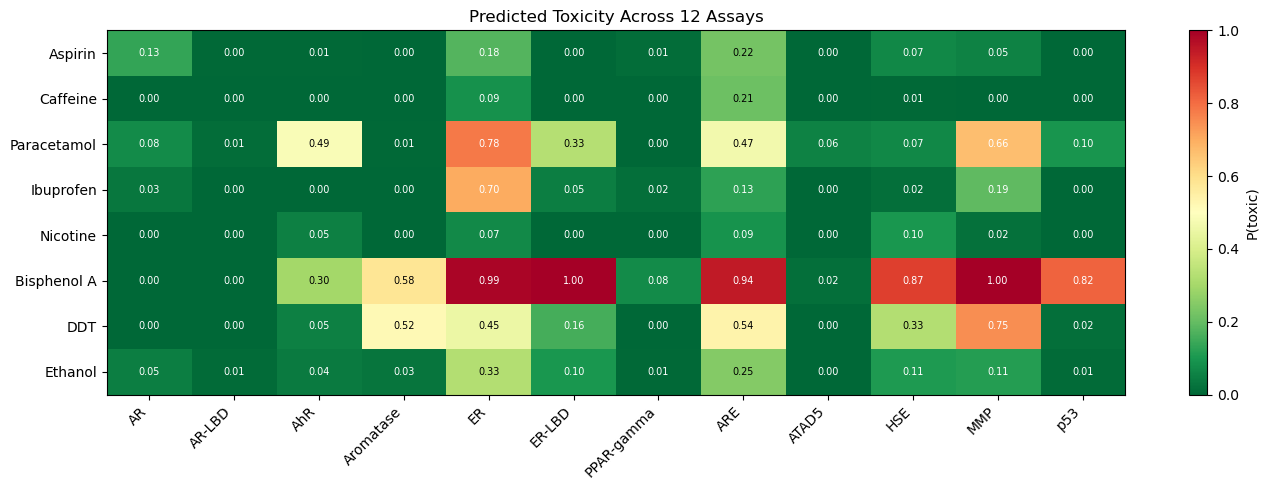

In [17]:
# Visualise toxicity heatmap for custom molecules
fig, ax = plt.subplots(figsize=(14, 5))
heatmap_data = np.array(all_probs)
tasks_short = [t.replace('NR-', '').replace('SR-', '') for t in tox21_tasks]

im = ax.imshow(heatmap_data, cmap='RdYlGn_r', aspect='auto', vmin=0, vmax=1)
ax.set_xticks(range(len(tasks_short)))
ax.set_xticklabels(tasks_short, rotation=45, ha='right')
ax.set_yticks(range(len(custom_names)))
ax.set_yticklabels(custom_names)
ax.set_title('Predicted Toxicity Across 12 Assays')

# Add text annotations
for i in range(len(custom_names)):
    for j in range(len(tox21_tasks)):
        val = heatmap_data[i, j]
        colour = 'white' if val > 0.6 or val < 0.2 else 'black'
        ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=7, color=colour)

plt.colorbar(im, ax=ax, label='P(toxic)')
plt.tight_layout()
plt.show()

## Summary

**Model**: MultitaskClassifier (hidden layers [512, 256]) on 1024-bit ECFP fingerprints, with multi-task classification across 12 Tox21 assays.

**Key findings**:
- Multi-task neural network outperforms single-task Random Forest, demonstrating the value of shared representations across related toxicity assays
- The model correctly identifies known toxic compounds (BPA, DDT) as higher risk and common drugs (ethanol, aspirin) as lower risk
- Class imbalance remains a challenge: assays with fewer positive examples (e.g. NR-AR, NR-AR-LBD) are harder to predict
- Scaffold splitting provides a more realistic evaluation than random splitting, as it tests generalisation to structurally novel compounds

**Relevance to GSoC 2026**: This exploration demonstrates familiarity with DeepChem's core abstractions (`MultitaskClassifier`, `MoleculeNet`, `Metric`, `Featurizer`, scaffold splitting) and molecular ML workflows. The SMILES-IUPAC translation project I am proposing will integrate into this same ecosystem, providing a complementary capability for chemical name-structure conversion.